Using Colab cache for faster access to the 'insurance' dataset.
Dataset Shape: (1338, 7)

First 10 Rows:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
5   31  female  25.740         0     no  southeast   3756.62160
6   46  female  33.440         1     no  southeast   8240.58960
7   37  female  27.740         3     no  northwest   7281.50560
8   37    male  29.830         2     no  northeast   6406.41070
9   60  female  25.840         0     no  northwest  28923.13692

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Charges Summary:
count     1338.000000
mean     13270.422265
s

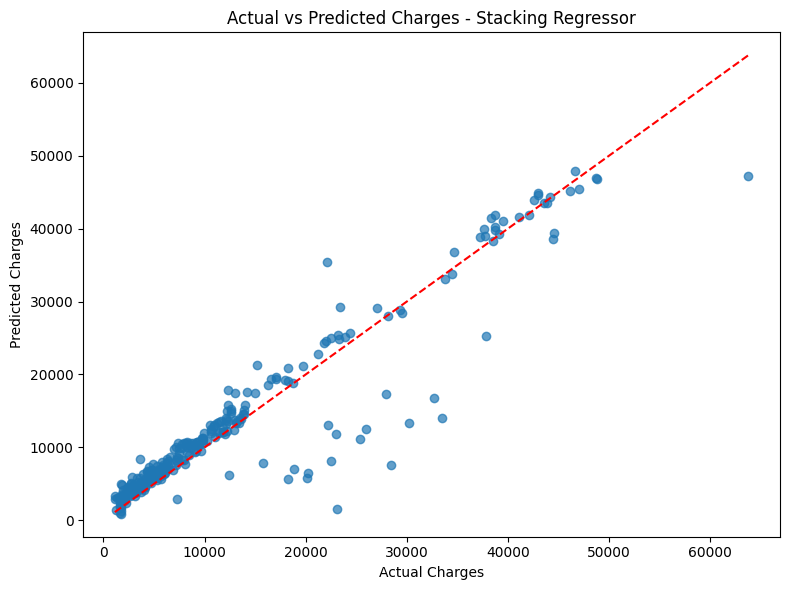


Best Model: Stacking Regressor
Best R2 Score: 0.880519518054329


In [1]:
#%% Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("mirichoi0218/insurance")

for file in os.listdir(path):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(path, file))
        break

print("Dataset Shape:", df.shape)
print("\nFirst 10 Rows:")
print(df.head(10))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCharges Summary:")
print(df["charges"].describe())

#%% Encode Categorical Columns
df["sex"] = df["sex"].map({"male": 1, "female": 0})
df["smoker"] = df["smoker"].map({"yes": 1, "no": 0})

df = pd.get_dummies(df, columns=["region"], drop_first=True, dtype=int)

#%% Split Dataset
X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#%% Define Base Models
ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

gb = GradientBoostingRegressor(
    random_state=42
)

#%% Train Individual Models
models = {
    "Ridge": ridge,
    "Random Forest": rf,
    "Gradient Boosting": gb
}

results = []

def evaluate_model(name, model):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

    return predictions

for name, model in models.items():
    evaluate_model(name, model)

#%% Stacking Regressor
stacking = StackingRegressor(
    estimators=[
        ("ridge", ridge),
        ("rf", rf),
        ("gb", gb)
    ],
    final_estimator=LinearRegression(),
    cv=5
)

stack_predictions = evaluate_model("Stacking Regressor", stacking)

#%% Compare All Models
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.to_string(index=False))

#%% Final Estimator Coefficients
final_model = stacking.final_estimator_

print("\nFinal Estimator Coefficients:")
for name, coefficient in zip(
    ["Ridge", "Random Forest", "Gradient Boosting"],
    final_model.coef_
):
    print(name, ":", coefficient)

print("\nFinal Estimator Intercept:", final_model.intercept_)

#%% Actual vs Predicted Charges
plt.figure(figsize=(8, 6))
plt.scatter(y_test, stack_predictions, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges - Stacking Regressor")
plt.tight_layout()
plt.show()

#%% Best Model
best_model = results_df.loc[results_df["R2 Score"].idxmax()]

print("\nBest Model:", best_model["Model"])
print("Best R2 Score:", best_model["R2 Score"])